<a href="https://colab.research.google.com/github/Saifuloh-411211122/Analikti_Visualisasi_Data/blob/main/Saifulloh_411211122_Forum-9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

print("Library terImport.")

Library terImport.


In [7]:
# Membuat atau membuka database
koneksi = sqlite3.connect("perpustakaan.db")

# Mengaktifkan pemeriksaan foreign key
koneksi.execute("PRAGMA foreign_keys = ON")

print("Database perpustakaan berhasil dibuat dan terhubung.")

Database perpustakaan berhasil dibuat dan terhubung.


In [8]:
cursor = koneksi.cursor()

# Tabel buku
cursor.execute("""
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
)
""")

# Tabel anggota
cursor.execute("""
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL
)
""")

# Tabel peminjaman
cursor.execute("""
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
""")

koneksi.commit()
print("Tabel buku, anggota, dan peminjaman berhasil dibuat.")

Tabel buku, anggota, dan peminjaman berhasil dibuat.


In [16]:
data_buku = [
    (1, "Matematika SMA Kelas X", "Marthen Kanginan", 2022),
    (2, "Bahasa Indonesia untuk SMA Kelas XI", "Suherli", 2021),
    (3, "Informatika untuk SMA Kelas X", "Kemdikbud", 2021),
    (4, "Sejarah Indonesia", "Hapsari", 2020),
    (5, "Pendidikan Pancasila", "Kemdikbud", 2023)
]

data_anggota = [
    (1, "Rahmat", "rahmat@gmail.com"),
    (2, "Kurniawan", "kurniawan@gmail.com"),
    (3, "Wati", "wati@gmail.com")
]

cursor.executemany(
    "INSERT OR IGNORE INTO buku (id, judul, penulis, tahun) VALUES (?, ?, ?, ?)",
    data_buku
)

cursor.executemany(
    "INSERT OR IGNORE INTO anggota (id, nama, email) VALUES (?, ?, ?)",
    data_anggota
)

koneksi.commit()

print("Data buku:")
display(pd.read_sql_query("SELECT * FROM buku", koneksi))

print("Data anggota:")
display(pd.read_sql_query("SELECT * FROM anggota", koneksi))

Data buku:


,id,judul,penulis,tahun
0,1,Matematika SMA Kelas X,Marthen Kanginan,2022
1,2,Bahasa Indonesia untuk SMA Kelas XI,Suherli,2021
2,3,Informatika untuk SMA Kelas X,Kemdikbud,2021
3,4,Sejarah Indonesia,Hapsari,2020
4,5,Pendidikan Pancasila,Kemdikbud,2023


Data anggota:


,id,nama,email
0,1,Rahmat,rahmat@gmail.com
1,2,Kurniawan,kurniawan@gmail.com
2,3,Wati,wati@gmail.com


In [35]:
data_peminjaman = [
    (1, 1, 1, "10-10-2026", "18-10-2026"),
    (2, 2, 2, "12-10-2026", "20-10-2026"),
    (3, 1, 3, "15-10-2026", "01-11-2026"),
    (4, 3, 4, "05-11-2026", None)
]

cursor.executemany(
    """
    INSERT OR IGNORE INTO peminjaman
    (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
    VALUES (?, ?, ?, ?, ?)
    """,
    data_peminjaman
)

koneksi.commit()

print("Data transaksi peminjaman:")
display(pd.read_sql_query("SELECT * FROM peminjaman", koneksi))

Data transaksi peminjaman:


,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,10-10-2026,18-10-2026
1,2,2,2,12-10-2026,20-10-2026
2,3,1,3,15-10-2026,01-11-2026
3,4,3,4,05-11-2026,None


In [36]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id
"""

hasil_join = pd.read_sql_query(query_join, koneksi)
display(hasil_join)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rahmat,Matematika SMA Kelas X,10-10-2026,18-10-2026
1,2,Kurniawan,Bahasa Indonesia untuk SMA Kelas XI,12-10-2026,20-10-2026
2,3,Rahmat,Informatika untuk SMA Kelas X,15-10-2026,01-11-2026
3,4,Wati,Sejarah Indonesia,05-11-2026,None


In [38]:
query_group = """
SELECT
    a.id,
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_peminjaman
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY a.id
"""

hasil_group = pd.read_sql_query(query_group, koneksi)
display(hasil_group)

,id,nama_anggota,jumlah_peminjaman
0,1,Rahmat,2
1,2,Kurniawan,1
2,3,Wati,1


In [39]:
df = pd.read_sql_query(query_join, koneksi)

print("Enam kolom data peminjaman:")
display(df)

print("Informasi DataFrame:")
df.info()

Enam kolom data peminjaman:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rahmat,Matematika SMA Kelas X,10-10-2026,18-10-2026
1,2,Kurniawan,Bahasa Indonesia untuk SMA Kelas XI,12-10-2026,20-10-2026
2,3,Rahmat,Informatika untuk SMA Kelas X,15-10-2026,01-11-2026
3,4,Wati,Sejarah Indonesia,05-11-2026,None


Informasi DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_peminjaman  4 non-null      int64 
 1   nama_anggota   4 non-null      object
 2   judul_buku     4 non-null      object
 3   tgl_pinjam     4 non-null      object
 4   tgl_kembali    3 non-null      object
dtypes: int64(1), object(4)
memory usage: 292.0+ bytes


In [41]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id
"""

hasil_join = pd.read_sql_query(query_join, koneksi)
display(hasil_join)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rahmat,Matematika SMA Kelas X,10-10-2026,18-10-2026
1,2,Kurniawan,Bahasa Indonesia untuk SMA Kelas XI,12-10-2026,20-10-2026
2,3,Rahmat,Informatika untuk SMA Kelas X,15-10-2026,01-11-2026
3,4,Wati,Sejarah Indonesia,05-11-2026,None


In [42]:
query_group = """
SELECT
    a.id,
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_peminjaman
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY a.id
"""

hasil_group = pd.read_sql_query(query_group, koneksi)
display(hasil_group)

,id,nama_anggota,jumlah_peminjaman
0,1,Rahmat,2
1,2,Kurniawan,1
2,3,Wati,1


In [43]:
df = pd.read_sql_query(query_join, koneksi)

print("Lima kolom data peminjaman:")
display(df)

print("Informasi DataFrame:")
df.info()

Lima kolom data peminjaman:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Rahmat,Matematika SMA Kelas X,10-10-2026,18-10-2026
1,2,Kurniawan,Bahasa Indonesia untuk SMA Kelas XI,12-10-2026,20-10-2026
2,3,Rahmat,Informatika untuk SMA Kelas X,15-10-2026,01-11-2026
3,4,Wati,Sejarah Indonesia,05-11-2026,None


Informasi DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_peminjaman  4 non-null      int64 
 1   nama_anggota   4 non-null      object
 2   judul_buku     4 non-null      object
 3   tgl_pinjam     4 non-null      object
 4   tgl_kembali    3 non-null      object
dtypes: int64(1), object(4)
memory usage: 292.0+ bytes


In [45]:

# Mengubah kolom tanggal menjadi tipe datetime
df["tgl_pinjam"] = pd.to_datetime(
    df["tgl_pinjam"],
    format="%d-%m-%Y"
)

df["tgl_kembali"] = pd.to_datetime(
    df["tgl_kembali"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Menghitung durasi peminjaman dalam hari
df["durasi_hari"] = (
    df["tgl_kembali"] - df["tgl_pinjam"]
).dt.days

# Membuat status pengembalian
df["status"] = df["tgl_kembali"].apply(
    lambda tanggal: "Sudah dikembalikan"
    if pd.notna(tanggal)
    else "Belum dikembalikan"
)

# Menampilkan hasil
display(df)


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari,status
0,1,Rahmat,Matematika SMA Kelas X,2026-10-10,2026-10-18,8.0,Sudah dikembalikan
1,2,Kurniawan,Bahasa Indonesia untuk SMA Kelas XI,2026-10-12,2026-10-20,8.0,Sudah dikembalikan
2,3,Rahmat,Informatika untuk SMA Kelas X,2026-10-15,2026-11-01,17.0,Sudah dikembalikan
3,4,Wati,Sejarah Indonesia,2026-11-05,NaT,NaN,Belum dikembalikan


In [46]:
# Ringkasan eksplorasi durasi transaksi yang sudah dikembalikan
durasi_valid = df["durasi_hari"].dropna()

print("Jumlah seluruh transaksi:", len(df))
print("Jumlah buku yang sudah dikembalikan:", len(durasi_valid))
print("Jumlah buku yang belum dikembalikan:", df["tgl_kembali"].isna().sum())

if len(durasi_valid) > 0:
    print("Rata-rata durasi peminjaman:", round(durasi_valid.mean(), 2), "hari")
    print("Durasi peminjaman terpendek:", durasi_valid.min(), "hari")
    print("Durasi peminjaman terlama:", durasi_valid.max(), "hari")
else:
    print("Belum ada transaksi yang selesai dikembalikan.")

Jumlah seluruh transaksi: 4
Jumlah buku yang sudah dikembalikan: 3
Jumlah buku yang belum dikembalikan: 1
Rata-rata durasi peminjaman: 11.0 hari
Durasi peminjaman terpendek: 8.0 hari
Durasi peminjaman terlama: 17.0 hari


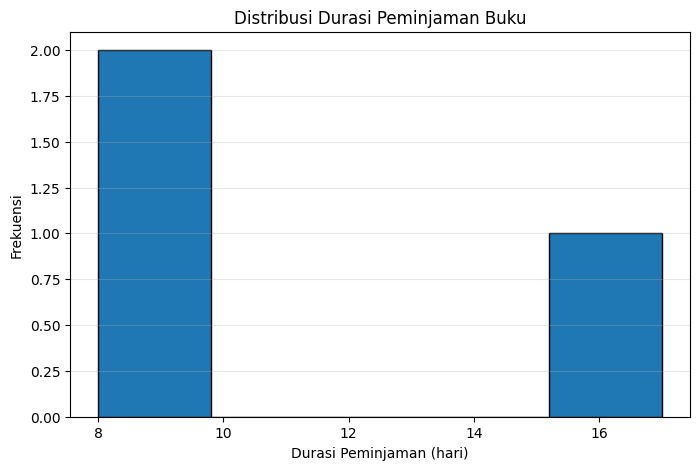

In [47]:
plt.figure(figsize=(8, 5))
plt.hist(durasi_valid, bins=5, edgecolor="black")
plt.title("Distribusi Durasi Peminjaman Buku")
plt.xlabel("Durasi Peminjaman (hari)")
plt.ylabel("Frekuensi")
plt.grid(axis="y", alpha=0.3)
plt.show()

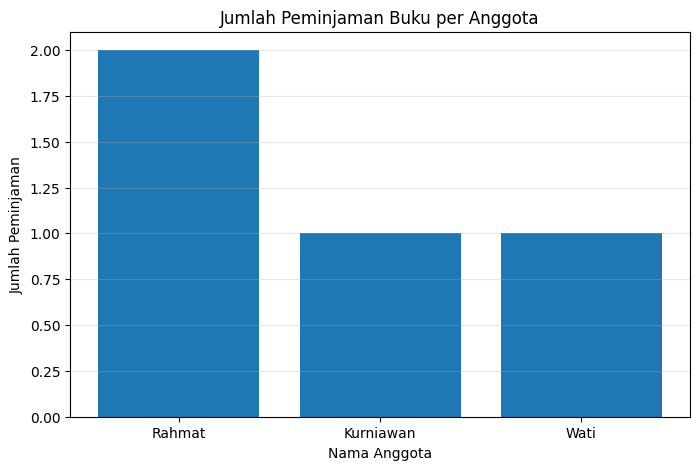

In [48]:
plt.figure(figsize=(8, 5))
plt.bar(hasil_group["nama_anggota"], hasil_group["jumlah_peminjaman"])
plt.title("Jumlah Peminjaman Buku per Anggota")
plt.xlabel("Nama Anggota")
plt.ylabel("Jumlah Peminjaman")
plt.grid(axis="y", alpha=0.3)
plt.show()